# Part 5c: does a market-rent incentive explain who keeps or loses affordability?

The state-level market variables (Part 5) and the project characteristics (Part 5b) did not explain what happens when subsidies end, which leaves one standard
hypothesis untested: **conversion incentive**. Where the market rent is far above the restricted rent, an owner has more to gain from leaving, so such places should
lose more affordable units; or, if strong markets attract new investors, they should rescue more. Either way the local gap between the market rent and the restricted rent should matter.

**Measure.** From the HUD HOME rent limits (`src/clean_home_rent_limits.py`; fiscal years 2019 and 2024): the county ratio of the 2-bedroom fair market rent to the rent affordable at 60 percent of area
median income (1.2 times the 50 percent HOME rent, the LIHTC level). Above 1 means the market rent exceeds the restricted rent. It is built by county, so it varies within a state, which is what lets us separate it from the
state effect that dominates Part 5b.

**Tests.** (1) The LIHTC exit model of Part 5b with the gap added; (2) the HOME and HUD-program rescue model of Part 5 with the gap added. Within-state variation, state-clustered standard errors, and an out-of-sample check on the same time splits.

In [1]:
import sys, warnings
sys.path.insert(0, "src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

import preservation as P
from viz import apply_style, SERIES, save_figure, SURFACE, MUTED, BASELINE, INK_2, dot

apply_style()
pd.set_option("display.width", 220)
h = pd.read_csv("data/interim/home_rent_limits_county.csv", dtype={"state_fips": str, "county_fips": str})

## 1. The gap

The market rent exceeds the 60 percent restricted rent in a growing share of counties.

,counties,fmr_2br_median,rent60_median,share_gap_above_1
year,,,,
2019,3143,732.0,895.2,0.17
2024,3144,952.0,1152.6,0.26


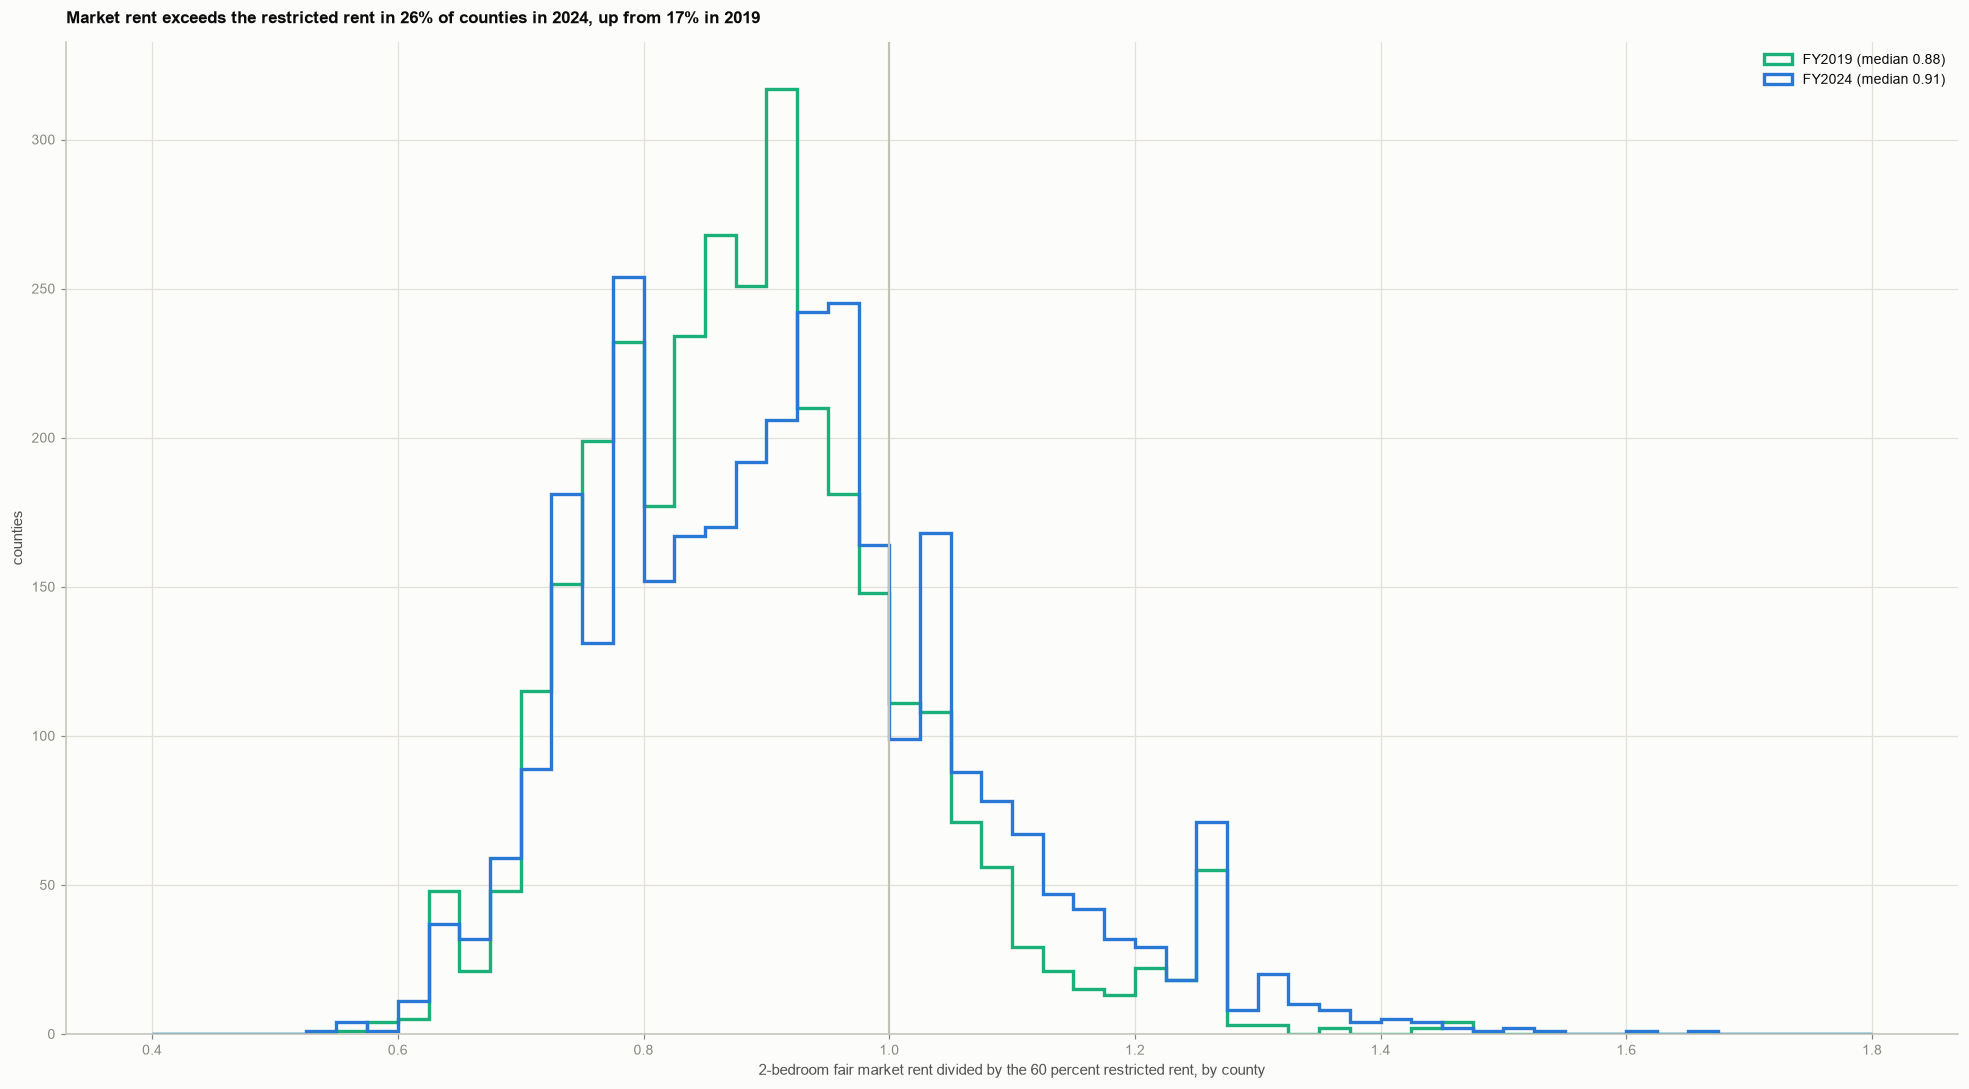

In [2]:
g = h.groupby("year").agg(counties=("county_fips", "size"), fmr_2br_median=("fmr_2", "median"), rent60_median=("rent60_2br", "median"), share_gap_above_1=("fmr_to_rent60_2br", lambda s: (s > 1).mean()))
display(g.round(2))
fig, ax = plt.subplots(figsize=(18, 10))
for y, c in ((2019, SERIES[2]), (2024, SERIES[0])):
    v = h[h.year == y].fmr_to_rent60_2br
    ax.hist(v, bins=np.linspace(0.4, 1.8, 57), histtype="step", lw=2.2, color=c, label=f"FY{y} (median {v.median():.2f})")
ax.axvline(1, color=BASELINE, lw=1.4)
ax.set_xlabel("2-bedroom fair market rent divided by the 60 percent restricted rent, by county"); ax.set_ylabel("counties")
ax.legend(frameon=False)
ax.set_title(f"Market rent exceeds the restricted rent in {100 * g.loc[2024, 'share_gap_above_1']:.0f}% of counties in 2024, up from {100 * g.loc[2019, 'share_gap_above_1']:.0f}% in 2019", fontsize=11, loc="left")
fig.tight_layout()
save_figure(fig, "53_gap_distribution", part="05_preservation")
plt.show()

## 2. LIHTC exit with the gap

Same sample as Part 5b (30-year allocations placed 1990 to 1995). Projects are matched to counties by the first complete tract code in the HUD file (95 percent matched). The gap is taken within state (deviation from the state mean, in national
standard deviations), so a coefficient says whether projects in a county with a larger gap than its neighbors in the state behave differently. Logit with state effects, states with no variation in the outcome dropped, standard errors clustered by state.

In [3]:
raw = pd.read_csv("data/interim/lihtc_projects.csv.gz", dtype={"state_fips": str, "county_fips": str})
c = raw[(raw.alloc_pre1990 == 0) & raw.pis_year.between(1990, 1995) & raw.n_units.notna()].copy()
for y in (2024, 2019):
    c = c.merge(h[h.year == y][["county_fips", "fmr_to_rent60_2br", "fmr_2"]].rename(columns={"fmr_to_rent60_2br": f"gap{y}", "fmr_2": f"fmr{y}"}), on="county_fips", how="left")
print(f"sample {len(c)} projects; matched to a county with a rent limit: {c.gap2024.notna().mean():.1%}")
c = c.dropna(subset=["gap2024", "gap2019"]).copy()
c["trend"] = c.pis_year - 1993
c["log_units"] = np.log(c.n_units); c["non_prof"] = c.non_prof.fillna(0.0); c["qct"] = c.qct.fillna(0.0); c["lfmr"] = np.log(c.fmr2024)

def within(df, col):
    return (df[col] - df.groupby("state_fips")[col].transform("mean")) / df[col].std()

def fe_logit(df, gapcol, extra=(), outcome="left_monitoring"):
    d = df.copy(); d["gz"] = within(d, gapcol)
    v = d.groupby("state_fips")[outcome].agg(["mean", "size"]); keep = v[(v["mean"] > 0) & (v["mean"] < 1) & (v["size"] >= 10)].index
    d = d[d.state_fips.isin(keep)]
    X = sm.add_constant(pd.concat([d[["trend", "gz"] + list(extra)].astype(float), pd.get_dummies(d.state_fips, drop_first=True, dtype=float)], axis=1))
    m = sm.Logit(d[outcome], X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": d.state_fips}, maxiter=300)
    return m, len(d), len(keep)

rows = []
for label, col, extra in (("rent gap, FY2024", "gap2024", ()), ("rent gap, FY2019", "gap2019", ()), ("rent gap, FY2024, with size, sponsor, tract controls", "gap2024", ("log_units", "non_prof", "qct")), ("market rent level (log FMR), FY2024", "lfmr", ())):
    m, n, k = fe_logit(c, col, extra)
    rows.append({"specification": label, "projects": n, "states": k, "coef": m.params["gz"], "se": m.bse["gz"], "t": m.tvalues["gz"], "p": m.pvalues["gz"], "odds ratio per SD": np.exp(m.params["gz"])})
lih = pd.DataFrame(rows).set_index("specification")
display(lih.round(3))

sample 7315 projects; matched to a county with a rent limit: 95.1%


,projects,states,coef,se,t,p,odds ratio per SD
specification,,,,,,,
"rent gap, FY2024",6836,46,0.025,0.126,0.198,0.843,1.025
"rent gap, FY2019",6836,46,-0.012,0.122,-0.101,0.920,0.988
"rent gap, FY2024, with size, sponsor, tract controls",6836,46,0.058,0.126,0.462,0.644,1.060
"market rent level (log FMR), FY2024",6836,46,0.036,0.135,0.267,0.790,1.037


In [4]:
tr, te = c[c.pis_year <= 1992].copy(), c[c.pis_year >= 1993].copy()
for d in (tr, te):
    d["gz24"] = within(c, "gap2024").reindex(d.index)
states = sorted(c.state_fips.unique())
def auc(cols, with_state=True):
    def X(df):
        parts = [df[cols].astype(float)] + ([pd.get_dummies(pd.Series(pd.Categorical(df.state_fips, categories=states), index=df.index), dtype=float)] if with_state else [])
        return pd.concat(parts, axis=1)
    xt, xe = X(tr), X(te); mu, sd = xt.mean(), xt.std().replace(0, 1)
    m = LogisticRegression(C=0.3, max_iter=5000).fit(((xt - mu) / sd).fillna(0), tr.left_monitoring)
    return roc_auc_score(te.left_monitoring, m.predict_proba(((xe - mu) / sd).fillna(0))[:, 1])
lih_auc = {"state effects + trend": auc(["trend"]), "plus within-state rent gap": auc(["trend", "gz24"]), "rent gap level only, no state effects": auc(["trend", "gap2024"], with_state=False)}
print("LIHTC exit, out of sample (train 1990-92, test 1993-95), AUC:", {k: round(v, 3) for k, v in lih_auc.items()})
c["q"] = pd.qcut(c.assign(gz=within(c, "gap2024")).gz, 5, labels=False)
print("share left monitoring by within-state gap quintile (low to high):", c.groupby("q").left_monitoring.mean().round(2).tolist())

LIHTC exit, out of sample (train 1990-92, test 1993-95), AUC: {'state effects + trend': 0.794, 'plus within-state rent gap': 0.793, 'rent gap level only, no state effects': 0.628}
share left monitoring by within-state gap quintile (low to high): [0.42, 0.53, 0.53, 0.54, 0.4]


## 3. HOME and HUD-program rescue with the gap

Same events as Part 5 (12,822 properties whose last subsidy lapsed 2011 to 2023). NHPD now carries a county for 99 percent of properties. Each event takes the FY2019 gap for lapses up to 2021 and the FY2024 gap after that. The gap is deviated from the
mean of its **state and vintage**, so the difference between the two vintages (and the rise in the rescue rate over the same years) cannot masquerade as an effect; the logit also has state and event-year effects.

In [5]:
ev = P.add_rent_gap(P.build_events())
d = ev.dropna(subset=["rent_gap_within"]).copy()
print(f"events with a county rent limit: {len(d)} of {len(ev)} ({len(d) / len(ev):.1%}); rescued {int(d.resub_3y.sum())}")
base_cols = ["log_total_units"] + [f"g_{x}" for x in P.GROUPS if x != "home_only"]

def fe_rescue(df, gap_col, year_fe=True):
    v = df.groupby("state_fips").resub_3y.agg(["sum", "size"]); keep = v[(v["sum"] > 0) & (v["size"] >= 30)].index
    x = df[df.state_fips.isin(keep)]
    parts = [x[base_cols + [gap_col]].astype(float), pd.get_dummies(x.state_fips, drop_first=True, dtype=float)] + ([pd.get_dummies(x.Y, drop_first=True, dtype=float)] if year_fe else [])
    X = sm.add_constant(pd.concat(parts, axis=1))
    return sm.Logit(x.resub_3y, X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": x.state_fips}, maxiter=300), len(x), len(keep)

d["gap_within_state_only"] = (d.rent_gap - d.groupby("state_fips").rent_gap.transform("mean")) / d.rent_gap.std()
rows = []
for label, col, yfe in (("within state only (vintages mixed), no year effects", "gap_within_state_only", False), ("within state and vintage, no year effects", "rent_gap_within", False), ("within state and vintage, with event-year effects", "rent_gap_within", True)):
    m, n, k = fe_rescue(d, col, yfe)
    rows.append({"specification": label, "events": n, "states": k, "coef": m.params[col], "se": m.bse[col], "t": m.tvalues[col], "p": m.pvalues[col]})
res = pd.DataFrame(rows).set_index("specification")
display(res.round(3))

rows = []
for split in ("main", "robust"):
    trn, tst = P.split(d, split); y = tst.resub_3y.values
    cols = P.FEATURE_SETS["size + program"]
    a0 = roc_auc_score(y, P.fit_predict(trn, tst, cols, "logit"))
    trn2, tst2 = trn.assign(rent_gap_within=trn.rent_gap_within.fillna(0)), tst.assign(rent_gap_within=tst.rent_gap_within.fillna(0))
    a1 = roc_auc_score(y, P.fit_predict(trn2, tst2, cols + ["rent_gap_within"], "logit"))
    a2 = roc_auc_score(y, P.fit_predict(trn2, tst2, cols + ["rent_gap_within"], "boosting"))
    rows.append({"split": split, "size + program (logit)": a0, "plus rent gap (logit)": a1, "plus rent gap (boosting)": a2})
resauc = pd.DataFrame(rows).set_index("split")
display(resauc.round(3))
Xl = sm.add_constant(pd.concat([d[base_cols].astype(float), ((d.rent_gap - d.rent_gap.mean()) / d.rent_gap.std()).rename("gap_level")], axis=1))
ml = sm.Logit(d.resub_3y, Xl).fit(disp=0, cov_type="cluster", cov_kwds={"groups": d.state_fips})
print(f"gap level with no state effects: coefficient {ml.params['gap_level']:.3f} (t {ml.tvalues['gap_level']:.1f})")

events with a county rent limit: 12613 of 12822 (98.4%); rescued 188


,events,states,coef,se,t,p
specification,,,,,,
"within state only (vintages mixed), no year effects",11389,36,0.241,0.103,2.334,0.020
"within state and vintage, no year effects",11389,36,0.049,0.083,0.586,0.558
"within state and vintage, with event-year effects",11389,36,0.047,0.095,0.492,0.623


,size + program (logit),plus rent gap (logit),plus rent gap (boosting)
split,,,
main,0.817,0.802,0.746
robust,0.833,0.814,0.768


gap level with no state effects: coefficient 0.263 (t 3.9)


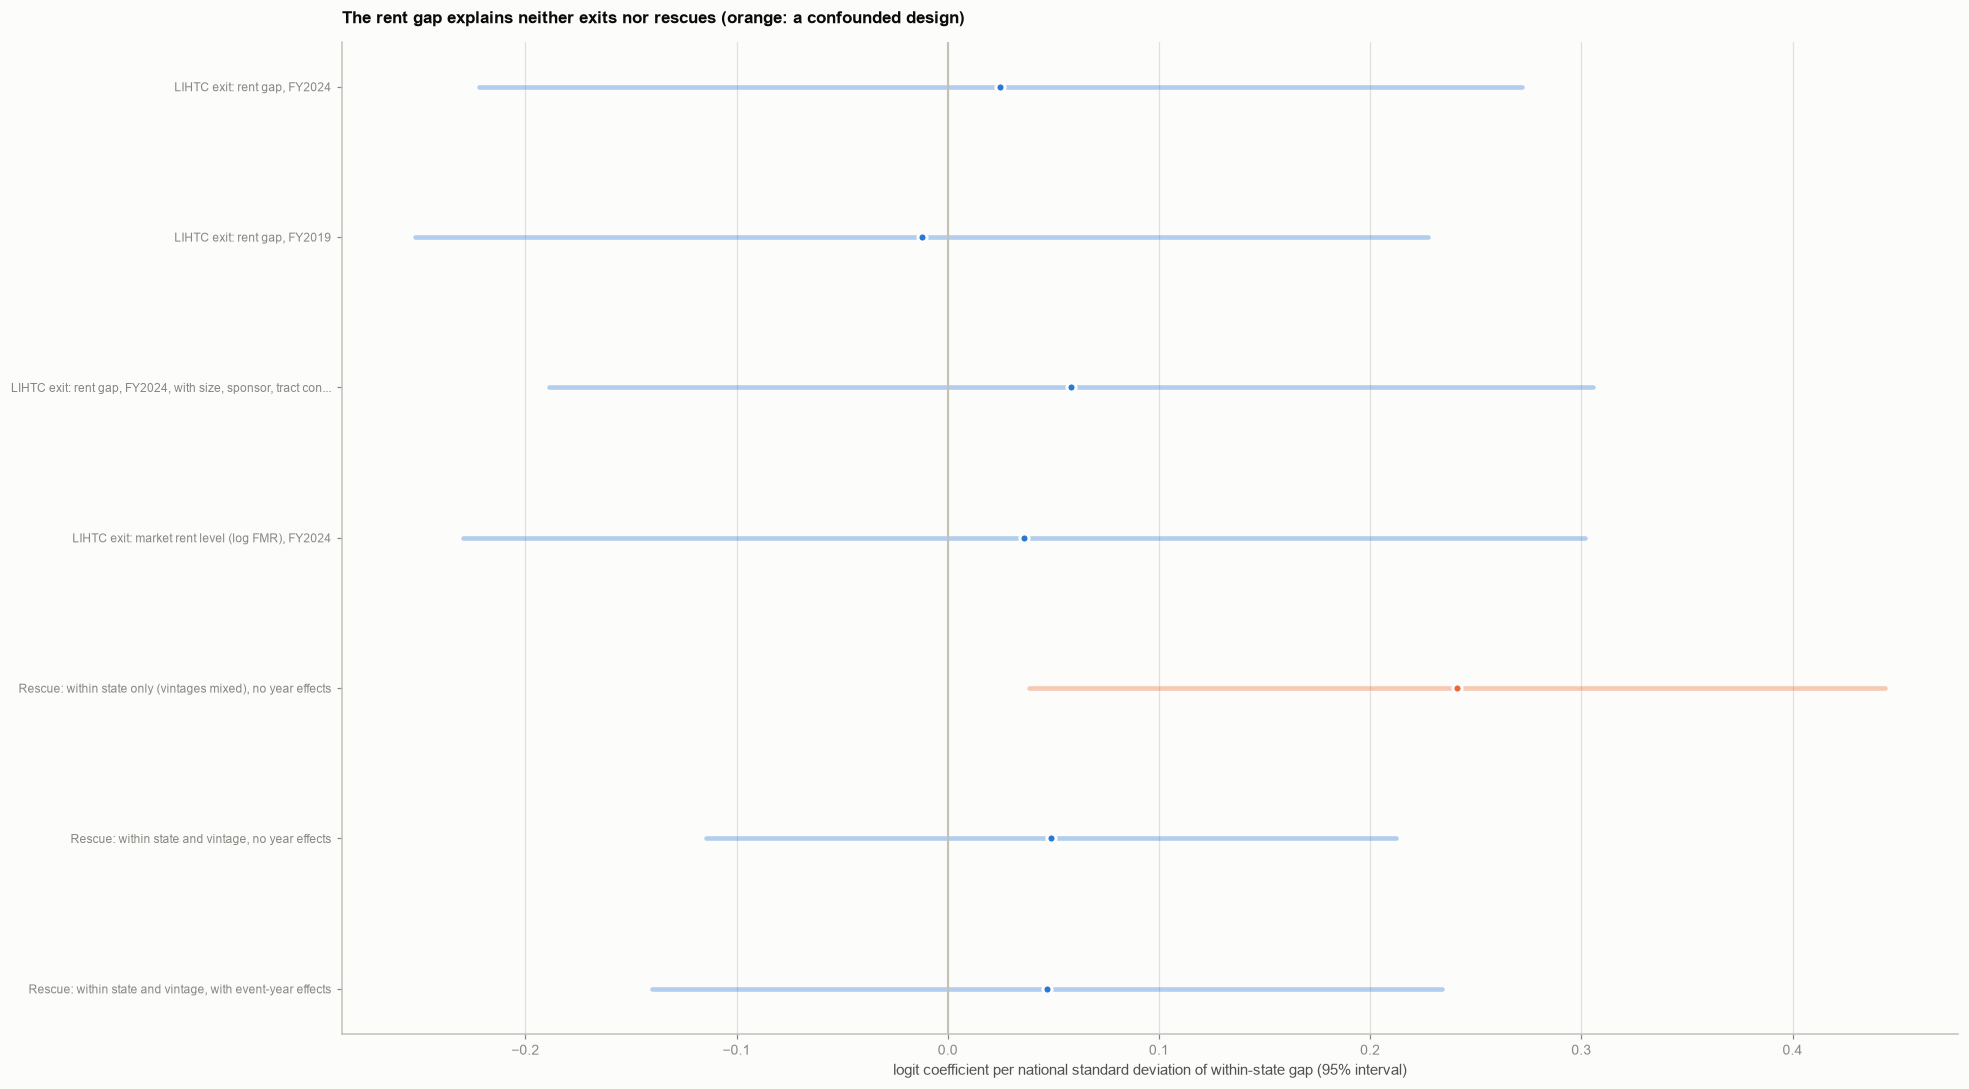

In [6]:
rows = [("LIHTC exit: " + k, v) for k, v in lih.iterrows()] + [("Rescue: " + k, v) for k, v in res.iterrows()]
fig, ax = plt.subplots(figsize=(18, 10))
labels = [r[0] for r in rows]
for i, (lab, r) in enumerate(rows):
    est, se = r["coef"], r["se"]
    c0 = SERIES[1] if "within state only (vintages mixed)" in lab else SERIES[0]
    ax.plot([est - 1.96 * se, est + 1.96 * se], [i, i], color=c0, alpha=0.35, lw=3, solid_capstyle="round")
    dot(ax, est, i, c0)
ax.axvline(0, color=BASELINE, lw=1.4)
ax.set_yticks(range(len(rows)), [l if len(l) < 62 else l[:59] + "..." for l in labels], fontsize=8); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("logit coefficient per national standard deviation of within-state gap (95% interval)")
ax.set_title("The rent gap explains neither exits nor rescues (orange: a confounded design)", fontsize=11, loc="left")
fig.tight_layout()
save_figure(fig, "53_gap_coefficients", part="05_preservation")
plt.show()

## Findings

**The market-incentive hypothesis is not supported, in either direction.** Neither the LIHTC exit model nor the HOME and HUD rescue model improves when the county gap between the fair market rent and the 60 percent restricted rent is added, and
the estimated effects are indistinguishable from zero with intervals tight enough to rule out large ones.

- **Measure.** HUD's HOME rent limits give the gap by county. The market rent exceeds the restricted 2-bedroom rent in 26 percent of counties in FY2024, up from 17 percent in FY2019 (median ratio 0.88 to 0.91).
- **LIHTC exit (6,836 projects in 46 states, 95 percent matched to a county).** Within a state, a county with a larger gap does not leave monitoring more or less often: coefficient +0.025 (t 0.20) for FY2024, -0.012 (t -0.10) for FY2019,
  +0.058 (t 0.46) with size, sponsor, and tract controls, and +0.036 (t 0.27) for the market rent level itself; the 95 percent intervals run about -0.25 to +0.30 per standard deviation (odds ratios roughly 0.8 to 1.35). Out of sample the AUC is 0.794 with state effects and
  0.793 with the gap added. The exit rate by within-state gap quintile is 42, 53, 53, 54, and 40 percent, a shape with no trend. The gap's level alone (no state effects) scores 0.63, but that only reflects which states are high-rent.
- **HOME and HUD-program rescue (11,389 events in 36 states, 98 percent matched).** A first specification that removed state means only gave a significant positive effect (+0.241, t 2.33, p = 0.020). It was an artifact: it mixed the FY2019 and FY2024 vintages, the FY2024 gaps are
  higher, and the rescue rate itself rose in 2022 and 2023. Removing state-and-vintage means gives +0.049 (t 0.59) and adding event-year effects +0.047 (t 0.49). Out of sample the AUC falls slightly (0.817 to 0.802 and 0.833 to 0.814 on the two splits; boosting is worse).
  Without state effects the gap's level is positively associated with rescue (+0.263, t 3.9), which describes where strong-rent counties are, not what predicts a rescue.
- **A correction to an earlier lead.** An exploratory look before this notebook matched only 57 percent of LIHTC projects (the 3-digit county field is blank or wrong for many, mostly in North Carolina, Pennsylvania, Indiana, Michigan, and Wisconsin) and suggested that a larger gap meant *fewer* exits
  (odds ratio 0.74, p = 0.046). With the proper county match (first complete tract code, 95 percent) the effect disappears. That lead should not be cited.

**What it means.** Whether subsidized housing is kept is driven by the size of the property (Part 5) and, for LIHTC, by the state (Part 5b), not by how far the local market rent sits above the restricted rent. Strong or weak local markets are not the lever; the places to look are monitoring practice and the tools states use at the end of the clock.

**Caveats.** Only two fiscal years of HOME rent limits are held (2019 and 2024), the market rent is HUD's fair market rent (a policy rent at the 40th percentile of recent movers, not observed rents), and the gap is measured now, not at the moment of each decision. The rescue model has 188 rescued events, so
small effects cannot be excluded. Files: `data/raw/home_rent_limits/` (HOME_Limits_Rents_2024.xlsx, 850,480 bytes; HOME_AllLimits_2019.xlsx, 1,718,572 bytes), `data/interim/home_rent_limits_county.csv`.